# P3 · Notebook 02a: Classical CV layer (visual quality), runs on CPU

**What this is:** the **visual** half of our quality gate, plus "safe polish", upscaling and packing for phones. It uses only classical image maths (OpenCV + NumPy), no neural networks.

> ⚠️ This judges **visual** quality only (blur, exposure, noise, tint, glitches). Whether the picture **matches the prompt** ("is the white cat there?") is the **semantic** check in notebook 02b. Classical CV can't do that part.

**What it proves, with numbers:**
1. **Detection:** we damage good photos on purpose (dark, washed-out, flat, tinted, blurry, grainy, blank, grid glitches) and check that each problem is **caught**, and that clean photos **don't** raise false alarms.
2. **Repair:** PSNR/SSIM against the undamaged original, before vs after the fix.
3. **Do no harm:** fixes are **accept-or-revert**. A fix is kept only if a re-check shows it solved the problem without creating a new one, including **added grain**. Clean pictures stay untouched.
4. **Escalation:** problems classical CV *can't* fix (real blur, blank) are sent back to the generator (cascade, notebook 02b).
5. **Upscaling:** our edge-aware upscaler vs nearest/bilinear/bicubic/Lanczos.
6. **Phone packing:** PNG vs JPEG vs WebP vs our "smallest file that still looks the same".
7. **Real generated pictures:** how often notebook 01's pictures get flagged, per setup.

**Honesty note:** the thresholds were tuned on 12 COCO photos. **Every number here is measured on 40 different (held-out) COCO photos** plus the generated pictures, so we're not testing on what we tuned on.

**How to run:** `Runtime → Change runtime type → CPU` (no GPU needed, and notebook 01 can keep the T4), then **Run all**. About 5–10 minutes.

## 1 · Settings

In [1]:
SAVE_TO_DRIVE = True        # results + figures go to Drive: P3_T2I/02a_classical_cv
N_HELDOUT = 40              # held-out COCO val photos (never used for tuning)
USE_INDEPENDENT_IQA = True  # BRISQUE (via the `piq` library) as an independent double-check of the fixes
SEED = 0

## 2 · Install (small, ~30 s)

In [2]:
import subprocess, sys
IQA_OK = False
r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tabulate"], capture_output=True, text=True)
if USE_INDEPENDENT_IQA:
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "piq"], capture_output=True, text=True)
    IQA_OK = r.returncode == 0
    print("piq installed (BRISQUE available)" if IQA_OK else "piq install failed, skipping BRISQUE:\n" + r.stderr[-400:])

piq installed (BRISQUE available)


## 3 · The classical CV module
This cell writes `p3_classical.py`, the same file that's in the GitHub repo (`src/p3_classical.py`). Notebooks 02b and 03 import it from Drive (`P3_T2I/shared/`).

In [3]:
%%writefile p3_classical.py
"""p3_classical.py: the classical computer-vision layer of our P3 text-to-image system.

No neural networks in here, only image maths (OpenCV + NumPy). This layer judges VISUAL quality only.
Whether the picture matches the prompt (semantic quality) is checked elsewhere (CLIP + detector, notebook 02b).

    assess(img, prompt)        no-reference visual check -> metrics, flags, verdict ("ok" / "fix" / "regenerate")
    safe_enhance(img, prompt)  fix only what was flagged, re-check, and KEEP THE FIX ONLY IF IT HELPED
    quality_maps(img)          per-region detail / noise maps (so fixes touch only the regions that need them)
    upscale(img, size)         classical resizing, incl. an edge-aware upscaler (Lanczos + back-projection)
    pack_for_mobile(img)       resize + smallest WebP/JPEG that keeps SSIM >= target
    psnr(a, b), ssim(a, b)     reference metrics for the experiments

Images are RGB uint8 numpy arrays (H, W, 3). to_rgb() converts PIL images.
"""
from __future__ import annotations

import time

import cv2
import numpy as np

ANALYSIS_SIZE = 512  # checks run on a copy with this longest side, so thresholds don't depend on resolution

# Thresholds, calibrated on real photos + synthetic damage (notebook 02a re-validates them on held-out images).
TH = {
    "blank_std": 4.0,           # brightness spread below this -> blank / broken
    "dark_mean": 90.0,          # too dark: mean brightness below this ...
    "dark_p95": 135.0,          # ... AND even the brightest 5% are dim
    "bright_mean": 170.0,       # too bright / washed out: mean above this ...
    "bright_p5": 110.0,         # ... AND even the darkest 5% are light
    "low_contrast": 0.10,       # RMS contrast (std / 255) below this -> flat
    "blur": 0.04,               # contrast-normalised sharpness below this -> blurry
    "noise_sigma": 3.8,         # noise estimated in flat areas (grey levels) above this -> grainy
    "cast_gray": 13.0,          # colour shift of the near-grey pixels above this -> tint. Deliberately conservative:
                                # warm scenes (brown fur, lamp light) also score high, so only strong tints count
    "periodic": 2.5,            # FFT spike strength above this -> grid / checkerboard glitch
}

# Do-no-harm guard: a fix may not raise the noise estimate by more than this (grey levels), e.g. CLAHE/sharpening on sky.
MAX_ADDED_GRAIN = 1.5   # brightening alone adds ~+0.3 (reveals shadow noise); gamma+CLAHE can reach +2

# Problems a classical fix can't really undo: if they remain, the cascade should generate again with more steps.
UNFIXABLE = {"blank", "blurry", "noisy", "periodic_artifact"}

# Words in the prompt that mean "this look is intended, don't fix it".
INTENT = {
    "too_dark": ["night", "dark", "noir", "silhouette", "midnight", "shadow", "candlelit", "moody", "low light", "starry"],
    "too_bright": ["bright white", "overexposed", "high key", "snow", "foggy white", "minimalist white"],
    "low_contrast": ["fog", "foggy", "mist", "haze", "hazy", "pastel", "soft light", "dreamy", "minimalist"],
    "colour_cast": ["sunset", "sunrise", "golden", "neon", "sepia", "monochrome", "black and white",
                    "underwater", "vintage", "duotone", "red light", "blue light", "candle", "warm", "autumn",
                    "fire", "desert", "lamp", "cozy", "cosy", "tungsten", "night city"],
    "blurry": ["bokeh", "blurry", "blurred", "motion blur", "out of focus", "depth of field", "dreamy",
               "fog", "foggy", "mist", "long exposure", "soft focus"],
    "noisy": ["film grain", "grainy", "noise", "noisy", "vintage photo", "analog"],
}


# ----------------------------------------------------------------------------- helpers
def to_rgb(img) -> np.ndarray:
    """PIL image / array -> RGB uint8 array (H, W, 3)."""
    if hasattr(img, "convert"):
        return np.asarray(img.convert("RGB")).copy()
    a = np.asarray(img)
    if a.ndim == 2:
        a = np.stack([a] * 3, axis=-1)
    if a.dtype != np.uint8:
        a = np.clip(a, 0, 255).astype(np.uint8)
    return np.ascontiguousarray(a[..., :3])


def _analysis_view(rgb: np.ndarray) -> np.ndarray:
    h, w = rgb.shape[:2]
    s = ANALYSIS_SIZE / max(h, w)
    if s < 1:
        rgb = cv2.resize(rgb, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    return rgb


def _gray(rgb: np.ndarray) -> np.ndarray:
    return cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)


def _edge_strength(gray: np.ndarray) -> np.ndarray:
    g = gray.astype(np.float32)
    mag = cv2.magnitude(cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3), cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3))
    return cv2.GaussianBlur(mag, (0, 0), 1.5)


# ----------------------------------------------------------------------------- metrics
def sharpness(gray: np.ndarray) -> float:
    """Variance of the Laplacian divided by brightness variance: high = crisp edges.
    Dividing by contrast means a dark or flat picture isn't wrongly called blurry."""
    g = gray.astype(np.float64)
    return float(cv2.Laplacian(g, cv2.CV_64F).var() / (g.var() + 1e-6))


def noise_sigma(gray: np.ndarray) -> float:
    """Immerkaer (1996) noise estimate, measured only in the flattest half of the picture
    (so texture and edges are not mistaken for noise). Unit: grey levels."""
    g = gray.astype(np.float64)
    k = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float64)
    resp = np.abs(cv2.filter2D(g, -1, k, borderType=cv2.BORDER_REFLECT))[1:-1, 1:-1]
    edges = _edge_strength(gray)[1:-1, 1:-1]
    flat = edges <= np.percentile(edges, 50)
    return float(np.sqrt(np.pi / 2) * resp[flat].mean() / 6.0)


def colourfulness(rgb: np.ndarray) -> float:
    """Hasler & Suesstrunk (2003) colourfulness: 0 = grey, ~30 = normal photo, 60+ = very colourful."""
    r, g, b = (rgb[..., i].astype(np.float64) for i in range(3))
    rg, yb = r - g, 0.5 * (r + g) - b
    return float(np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean()))


def colour_cast(rgb: np.ndarray) -> tuple[float, float]:
    """Tint test in LAB on the NEAR-GREY pixels (the least colourful 15%, ignoring very dark/bright ones).
    In a normal picture those pixels are close to neutral, even if the scene is colourful (a red car, green grass).
    If even they are pushed towards one colour, the whole picture has a tint.
    Returns (shift of near-grey pixels, average shift of all pixels), both in LAB units."""
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float64)
    L, a, b = lab[..., 0], lab[..., 1] - 128.0, lab[..., 2] - 128.0
    chroma = np.hypot(a, b)
    mid = (L > 40) & (L < 235)
    if mid.sum() < 100:
        mid = np.ones_like(L, bool)
    grayish = mid & (chroma <= np.percentile(chroma[mid], 15))
    gray_shift = float(np.hypot(a[grayish].mean(), b[grayish].mean()))
    return gray_shift, float(np.hypot(a.mean(), b.mean()))


def _spectrum_residual(gray: np.ndarray):
    """Log-magnitude spectrum minus its smooth background. Isolated spikes = periodic patterns."""
    g = gray.astype(np.float32)
    g = g - g.mean()
    h, w = g.shape
    win = np.outer(np.hanning(h), np.hanning(w)).astype(np.float32)
    spec = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(g * win)))).astype(np.float32)
    bg = cv2.GaussianBlur(spec, (0, 0), 3.0, borderType=cv2.BORDER_REFLECT_101)
    yy, xx = np.ogrid[:h, :w]
    r = np.hypot((yy - h // 2) / (h / 2), (xx - w // 2) / (w / 2))  # 0 = DC, 1 = Nyquist
    return spec - bg, r > 0.25  # ignore low frequencies (normal picture content lives there)


def periodic_score(gray: np.ndarray) -> float:
    resid, mask = _spectrum_residual(gray)
    return float(resid[mask].max())


# ----------------------------------------------------------------------------- 1. assess
def _intended(flag: str, prompt: str | None) -> bool:
    p = (prompt or "").lower()
    return any(word in p for word in INTENT.get(flag, []))


def assess(img, prompt: str | None = None) -> dict:
    """Visual quality check. Returns metrics, flags, ignored (flags the prompt asked for), verdict, qa_score."""
    rgb = _analysis_view(to_rgb(img))
    gray = _gray(rgb)
    g = gray.astype(np.float64)
    cast_gray, cast_all = colour_cast(rgb)
    m = {
        "mean": g.mean(), "p5": np.percentile(g, 5), "p95": np.percentile(g, 95), "std": g.std(),
        "contrast_rms": g.std() / 255.0, "sharpness": sharpness(gray), "noise_sigma": noise_sigma(gray),
        "colourfulness": colourfulness(rgb), "cast_gray": cast_gray, "cast_all": cast_all,
        "periodic": periodic_score(gray),
    }
    raw = []
    if m["std"] < TH["blank_std"]:
        raw.append("blank")
    else:
        if m["mean"] < TH["dark_mean"] and m["p95"] < TH["dark_p95"]:
            raw.append("too_dark")
        if m["mean"] > TH["bright_mean"] and m["p5"] > TH["bright_p5"]:
            raw.append("too_bright")
        if m["contrast_rms"] < TH["low_contrast"]:
            raw.append("low_contrast")
        if m["sharpness"] < TH["blur"]:
            raw.append("blurry")
        if m["noise_sigma"] > TH["noise_sigma"]:
            raw.append("noisy")
        if m["cast_gray"] > TH["cast_gray"]:
            raw.append("colour_cast")
        if m["periodic"] > TH["periodic"]:
            raw.append("periodic_artifact")
    flags = [f for f in raw if f == "blank" or not _intended(f, prompt)]
    ignored = [f for f in raw if f not in flags]
    verdict = "regenerate" if "blank" in flags else ("fix" if flags else "ok")
    return {
        "metrics": {key: float(v) for key, v in m.items()},
        "flags": flags,
        "ignored_by_prompt": ignored,
        "verdict": verdict,
        "qa_score": 0 if "blank" in flags else max(0, 100 - 15 * len(flags)),
    }


# ----------------------------------------------------------------------------- 2. corrections
def guided_filter(guide: np.ndarray, src: np.ndarray, r: int, eps: float) -> np.ndarray:
    """He et al. (2010) guided filter: edge-preserving smoothing in O(N). guide: gray uint8, src: uint8 (H,W[,3]).
    Returns float32 in [0, 1]."""
    I = guide.astype(np.float32) / 255.0
    p = src.astype(np.float32) / 255.0
    if p.ndim == 3:
        I = I[..., None]

    def box(x):
        y = cv2.boxFilter(x, -1, (2 * r + 1, 2 * r + 1), borderType=cv2.BORDER_REFLECT)
        return y[..., None] if (x.ndim == 3 and y.ndim == 2) else y

    mean_I, mean_p = box(I), box(p)
    a = (box(I * p) - mean_I * mean_p) / (box(I * I) - mean_I * mean_I + eps)
    b = mean_p - a * mean_I
    return box(a) * I + box(b)


def remove_periodic(rgb: np.ndarray, thresh: float | None = None) -> tuple[np.ndarray, int]:
    """Notch filter: find spikes in the frequency spectrum and push them down to the background level."""
    thresh = TH["periodic"] if thresh is None else thresh
    resid, mask = _spectrum_residual(_gray(rgb))
    peaks = (resid > thresh) & mask
    n = int(peaks.sum())
    if n == 0:
        return rgb, 0
    peaks = np.fft.ifftshift(cv2.dilate(peaks.astype(np.uint8), np.ones((5, 5), np.uint8)) > 0)
    out = np.empty(rgb.shape, np.float32)
    for c in range(3):
        F = np.fft.fft2(rgb[..., c].astype(np.float32))
        logmag = np.log1p(np.abs(F)).astype(np.float32)
        excess = logmag - cv2.GaussianBlur(logmag, (0, 0), 3.0, borderType=cv2.BORDER_REFLECT_101)
        # each channel's own spike height (measured without the window) is pushed down to its local background
        atten = np.where(peaks, np.exp(-np.clip(excess, 0, None)), 1.0)
        out[..., c] = np.real(np.fft.ifft2(F * atten))
    return np.clip(out, 0, 255).astype(np.uint8), n


def denoise(rgb: np.ndarray) -> tuple[np.ndarray, float]:
    """Edge-preserving bilateral filter, applied mainly in flat regions (textures and edges are kept)."""
    sigma = noise_sigma(_gray(rgb))
    den = cv2.bilateralFilter(rgb, 7, sigmaColor=max(10.0, 3.0 * sigma), sigmaSpace=3)
    den = cv2.bilateralFilter(den, 5, sigmaColor=max(10.0, 2.0 * sigma), sigmaSpace=2)
    e = _edge_strength(_gray(den))   # edges measured on the cleaned picture, so noise isn't mistaken for edges
    flat = 1.0 - np.clip(e / (np.percentile(e, 90) + 1e-6), 0, 1)
    out = flat[..., None] * den.astype(np.float32) + (1 - flat[..., None]) * rgb.astype(np.float32)
    return np.clip(out, 0, 255).astype(np.uint8), sigma


def white_balance(rgb: np.ndarray, strength: float = 0.8) -> np.ndarray:
    """Gray-pixel white balance (a gray-world variant) in LAB: measure the tint on the near-grey pixels only,
    then shift the whole picture back by `strength` of it. Colourful objects don't fool it."""
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
    L, a, b = lab[..., 0], lab[..., 1] - 128.0, lab[..., 2] - 128.0
    chroma = np.hypot(a, b)
    mid = (L > 40) & (L < 235)
    if mid.sum() < 100:
        mid = np.ones_like(L, bool)
    grayish = mid & (chroma <= np.percentile(chroma[mid], 15))
    lab[..., 1] -= strength * a[grayish].mean()
    lab[..., 2] -= strength * b[grayish].mean()
    return cv2.cvtColor(np.clip(lab, 0, 255).astype(np.uint8), cv2.COLOR_LAB2RGB)


def auto_gamma(rgb: np.ndarray, target: float = 0.45) -> tuple[np.ndarray, float]:
    """Gamma on brightness only (LAB L channel) so the average lands near `target`. Colours are kept."""
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    mean = max(lab[..., 0].mean() / 255.0, 1e-3)
    gamma = float(np.clip(np.log(target) / np.log(mean), 0.45, 2.2))
    lut = (255.0 * (np.arange(256) / 255.0) ** gamma).clip(0, 255).astype(np.uint8)
    lab[..., 0] = cv2.LUT(lab[..., 0], lut)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB), gamma


def clahe(rgb: np.ndarray, clip: float = 2.0, tiles: int = 8) -> np.ndarray:
    """CLAHE (local contrast) on brightness only."""
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tiles, tiles)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)


def edge_aware_sharpen(rgb: np.ndarray, amount: float) -> np.ndarray:
    """Boost detail ONLY around edges: detail = image - guided-filter base, weighted by an edge mask.
    Flat areas (sky, skin) are left alone, so noise isn't amplified and halos stay small."""
    gray = _gray(rgb)
    base = guided_filter(gray, rgb, r=2, eps=1e-3)
    img = rgb.astype(np.float32) / 255.0
    e = _edge_strength(gray)
    mask = np.clip(e / (np.percentile(e, 95) + 1e-6), 0, 1)[..., None]
    return np.clip((img + amount * (img - base) * mask) * 255.0, 0, 255).astype(np.uint8)


def _apply_fixes(rgb: np.ndarray, rep: dict, stages: list | None, prompt: str | None):
    m, flags, actions, out = rep["metrics"], rep["flags"], [], rgb

    def log(name, img):
        actions.append(name)
        if stages is not None:
            stages.append((name, img))

    if "periodic_artifact" in flags:
        out, n = remove_periodic(out)
        log(f"notch filter (removed {n} spectrum spikes)", out)
        rep = assess(out, prompt)          # a grid also looks like noise: re-check before the next fixes
        m, flags = rep["metrics"], rep["flags"]
    if "noisy" in flags:
        out, sigma = denoise(out)
        log(f"edge-preserving denoise (noise sigma {sigma:.1f})", out)
    if "colour_cast" in flags:
        out = white_balance(out, 0.6)
        log(f"gray-pixel white balance (tint {m['cast_gray']:.1f} LAB units)", out)
    if "too_dark" in flags or "too_bright" in flags:
        out, gamma = auto_gamma(out)
        log(f"gamma on brightness (gamma {gamma:.2f})", out)
    # CLAHE for flat pictures. Dark pictures get it only if they're STILL flat after gamma:
    # on dark pictures CLAHE mostly amplifies grain in smooth areas (sky, walls).
    contrast_now = _gray(out).std() / 255.0
    if "low_contrast" in flags or contrast_now < TH["low_contrast"]:
        clip = float(np.clip(1.5 + 15 * (TH["low_contrast"] - contrast_now), 1.5, 3.0))
        out = clahe(out, clip)
        log(f"CLAHE local contrast (clip {clip:.1f})", out)
    if "blurry" in flags:
        amount = float(np.clip(0.6 + 2.0 * (TH["blur"] - m["sharpness"]) / TH["blur"], 0.6, 1.8))
        out = edge_aware_sharpen(out, amount)
        log(f"edge-aware sharpen (amount {amount:.2f})", out)
    return out, actions


def safe_enhance(img, prompt: str | None = None, return_stages: bool = False) -> tuple[np.ndarray, dict]:
    """Fix only what assess() flagged, then RE-CHECK. Keep the fix only if
    (1) at least one flagged problem is gone or clearly better, and (2) no new problem appeared.
    Otherwise return the original picture untouched ("do no harm")."""
    t0 = time.perf_counter()
    rgb = to_rgb(img)
    before = assess(rgb, prompt)
    stages = [("input", rgb)] if return_stages else None
    info = {"before": before, "after": None, "actions": [], "accepted": False, "decision": "",
            "escalate": False, "stages": stages}

    if before["verdict"] == "regenerate":
        info.update(escalate=True, decision="blank/broken: nothing to fix, ask the generator for a new picture")
    elif before["verdict"] == "ok":
        info["decision"] = "no visual problems: original kept"
    else:
        out, actions = _apply_fixes(rgb, before, stages, prompt)
        after = assess(out, prompt)
        fixed = [f for f in before["flags"] if f not in after["flags"]]
        new = [f for f in after["flags"] if f not in before["flags"]]
        grain_added = after["metrics"]["noise_sigma"] - before["metrics"]["noise_sigma"]
        if "noisy" not in before["flags"] and grain_added > MAX_ADDED_GRAIN:
            new.append(f"added_grain(+{grain_added:.1f})")   # a fix must not make smooth areas grainy
        info.update(after=after, actions=actions)
        if fixed and not new:
            info.update(accepted=True, decision=f"fix kept: solved {fixed}")
            rgb = out
            remaining = after["flags"]
        else:
            info["decision"] = f"fix rejected (solved {fixed}, new problems {new}): original kept"
            remaining = before["flags"]
        # Classical CV can't undo real blur, heavy noise or broken structure -> the cascade should spend more steps.
        unfixable = [f for f in remaining if f in UNFIXABLE]
        if unfixable:
            info.update(escalate=True, decision=info["decision"] + f"; still {unfixable}: escalate to a higher rung")
    info["ms"] = (time.perf_counter() - t0) * 1000
    return rgb, info


# ----------------------------------------------------------------------------- 3. region maps (visualisation)
def quality_maps(img, tile: int = 32) -> dict:
    """Per-tile detail (sharpness) and noise maps on the analysis-size picture, for 'where is it bad?' views."""
    gray = _gray(_analysis_view(to_rgb(img)))
    h, w = gray.shape
    rows, cols = h // tile, w // tile
    detail, noise = np.zeros((rows, cols)), np.zeros((rows, cols))
    lap = cv2.Laplacian(gray.astype(np.float64), cv2.CV_64F)
    for i in range(rows):
        for j in range(cols):
            sl = (slice(i * tile, (i + 1) * tile), slice(j * tile, (j + 1) * tile))
            detail[i, j] = lap[sl].var()
            noise[i, j] = noise_sigma(gray[sl])
    return {"detail": detail, "noise": noise}


# ----------------------------------------------------------------------------- 4. resizing
_INTERP = {"nearest": cv2.INTER_NEAREST, "bilinear": cv2.INTER_LINEAR,
           "bicubic": cv2.INTER_CUBIC, "lanczos": cv2.INTER_LANCZOS4}


def upscale(img, size: tuple[int, int], method: str = "edge_aware", iters: int = 4) -> np.ndarray:
    """Resize to size=(width, height). 'edge_aware' = Lanczos + iterative back-projection
    (Irani & Peleg 1991): repeatedly fix the big picture so that shrinking it gives back the small one."""
    rgb = to_rgb(img)
    W, H = size
    if method in _INTERP:
        return cv2.resize(rgb, (W, H), interpolation=_INTERP[method])
    if method != "edge_aware":
        raise ValueError(f"unknown method {method!r}")
    h, w = rgb.shape[:2]
    lr = rgb.astype(np.float32)
    x = cv2.resize(lr, (W, H), interpolation=cv2.INTER_LANCZOS4)
    for _ in range(iters):
        err = lr - cv2.resize(x, (w, h), interpolation=cv2.INTER_AREA)
        x += cv2.resize(err, (W, H), interpolation=cv2.INTER_CUBIC)
    return np.clip(x, 0, 255).astype(np.uint8)


# ----------------------------------------------------------------------------- 5. reference metrics
def psnr(a, b) -> float:
    mse = np.mean((to_rgb(a).astype(np.float64) - to_rgb(b).astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else float(10 * np.log10(255.0 ** 2 / mse))


def ssim(a, b) -> float:
    """Standard SSIM (Wang et al. 2004) on brightness, 11x11 Gaussian window."""
    x, y = (_gray(to_rgb(i)).astype(np.float64) for i in (a, b))
    c1, c2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2

    def blur(z):
        return cv2.GaussianBlur(z, (11, 11), 1.5)

    mx, my = blur(x), blur(y)
    vx, vy, cxy = blur(x * x) - mx * mx, blur(y * y) - my * my, blur(x * y) - mx * my
    return float((((2 * mx * my + c1) * (2 * cxy + c2)) / ((mx * mx + my * my + c1) * (vx + vy + c2))).mean())


# ----------------------------------------------------------------------------- 6. packing for phones
def encode(img, fmt: str = "webp", quality: int = 85) -> bytes:
    bgr = cv2.cvtColor(to_rgb(img), cv2.COLOR_RGB2BGR)
    fmt = fmt.lower()
    if fmt == "png":
        ok, buf = cv2.imencode(".png", bgr, [cv2.IMWRITE_PNG_COMPRESSION, 6])
    elif fmt in ("jpg", "jpeg"):
        ok, buf = cv2.imencode(".jpg", bgr, [cv2.IMWRITE_JPEG_QUALITY, int(quality)])
    elif fmt == "webp":
        ok, buf = cv2.imencode(".webp", bgr, [cv2.IMWRITE_WEBP_QUALITY, int(quality)])
    else:
        raise ValueError(f"unknown format {fmt!r}")
    if not ok:
        raise RuntimeError(f"encoding to {fmt} failed")
    return buf.tobytes()


def decode(data: bytes) -> np.ndarray:
    return cv2.cvtColor(cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)


def pack_for_mobile(img, max_side: int = 1024, fmt: str = "webp", min_ssim: float = 0.95,
                    q_lo: int = 30, q_hi: int = 95) -> tuple[bytes, dict]:
    """Shrink to the phone's size, then binary-search the SMALLEST quality whose SSIM >= min_ssim.
    SSIM is measured on a <=512px copy to keep the search fast (~5 encodes)."""
    t0 = time.perf_counter()
    rgb = to_rgb(img)
    h, w = rgb.shape[:2]
    if max(h, w) > max_side:
        s = max_side / max(h, w)
        rgb = cv2.resize(rgb, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    # Search the quality on a <=512px copy (fast), then encode the full-size picture once.
    ref = _analysis_view(rgb)
    best_q = q_hi
    lo, hi = q_lo, q_hi
    while lo <= hi:
        q = (lo + hi) // 2
        if ssim(ref, decode(encode(ref, fmt, q))) >= min_ssim:
            best_q, hi = q, q - 2
        else:
            lo = q + 2
    q = best_q
    data = encode(rgb, fmt, q)
    s_val = ssim(ref, _analysis_view(decode(data)))
    return data, {"format": fmt, "quality": q, "kb": len(data) / 1024, "ssim": s_val,
                  "size": rgb.shape[1::-1], "ms": (time.perf_counter() - t0) * 1000}

Writing p3_classical.py


In [4]:
import os, json, time, shutil, importlib, textwrap, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from IPython.display import display

import p3_classical as pcv
importlib.reload(pcv)
print("OpenCV", cv2.__version__, "| thresholds:", pcv.TH)

OUT = Path(os.environ.get("P3_OUT", "/content/P3_02a_out"))
DATA = Path(os.environ.get("P3_DATA", "/content/p3_02a_data"))
NB01_HARD = Path(os.environ.get("P3_NB01_HARD", "/content/drive/MyDrive/P3_T2I/01_optimization_lab/hard_prompts"))
if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT = Path("/content/drive/MyDrive/P3_T2I/02a_classical_cv")
        shared = Path("/content/drive/MyDrive/P3_T2I/shared")
        shared.mkdir(parents=True, exist_ok=True)
        shutil.copy("p3_classical.py", shared / "p3_classical.py")
        print("Module copied to", shared)
    except Exception as e:
        print("Google Drive not available, saving locally:", e)
FIG = OUT / "figures"
for d in (OUT, FIG, DATA):
    d.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)
print("Results folder:", OUT)

OpenCV 5.0.0 | thresholds: {'blank_std': 4.0, 'dark_mean': 90.0, 'dark_p95': 135.0, 'bright_mean': 170.0, 'bright_p5': 110.0, 'low_contrast': 0.1, 'blur': 0.04, 'noise_sigma': 3.8, 'cast_gray': 13.0, 'periodic': 2.5}
Mounted at /content/drive
Module copied to /content/drive/MyDrive/P3_T2I/shared
Results folder: /content/drive/MyDrive/P3_T2I/02a_classical_cv


## 4 · Data: held-out COCO photos + generated pictures from notebook 01

In [5]:
CALIBRATION_IDS = [139, 285, 632, 724, 776, 785, 802, 872, 885, 1000, 1268, 39769]   # used for tuning, NOT used here
HELDOUT_IDS = [1296, 1353, 1425, 1490, 1503, 1532, 1584, 1675, 1761, 1818, 1993, 2006, 2149, 2153, 2157,
               2261, 2299, 2431, 2473, 2532, 2587, 2592, 2685, 2923, 3156, 3255, 3501, 3553, 3661, 3845,
               3934, 4134, 4395, 4495, 4765, 4795, 5001, 5037, 5060, 5193, 5477, 5503, 5529, 5586, 5600][:N_HELDOUT]
assert not set(HELDOUT_IDS) & set(CALIBRATION_IDS), "held-out photos must differ from the tuning photos"

def load_rgb(path):
    return cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)

def center512(rgb):
    h, w = rgb.shape[:2]
    s = min(h, w)
    rgb = rgb[(h - s) // 2:(h - s) // 2 + s, (w - s) // 2:(w - s) // 2 + s]
    return cv2.resize(rgb, (512, 512), interpolation=cv2.INTER_AREA)

photos = []
for iid in HELDOUT_IDS:
    f = DATA / f"{iid:012d}.jpg"
    if not f.exists():
        urllib.request.urlretrieve(f"http://images.cocodataset.org/val2017/{iid:012d}.jpg", f)
    photos.append(center512(load_rgb(f)))
print(f"{len(photos)} held-out COCO photos (512x512)")

# Same 12 hard prompts as notebook 01, so we know which prompt each generated picture came from
HARD_PROMPTS = [
    "a red cube on top of a blue sphere, next to a sleeping orange cat, studio lighting",
    "two cats on a blue sofa, the black cat on the left and the white cat on the right",
    "a teddy bear wearing sunglasses reading a newspaper on a park bench",
    "a green vintage car parked under a streetlight on a rainy night, reflections on the wet road",
    "a glass of orange juice and a croissant on a white plate, a laptop in the background, morning light",
    "an astronaut riding a horse on a red desert planet, two moons in the sky",
    "a bowl of ramen with a soft-boiled egg, chopsticks resting on the bowl, top-down view",
    "a lighthouse on a cliff during a storm, huge waves, dramatic clouds",
    "a small yellow bird sitting on a big purple flower, blurry green background",
    "a dog to the left of a bicycle and a red umbrella to the right of the bicycle",
    "exactly five apples in a woven basket on a kitchen table",
    "a wooden sign that says OPEN hanging on a shop door",
]
generated = []   # (setup, prompt_index, prompt, rgb)
if NB01_HARD.exists():
    for d in sorted(p for p in NB01_HARD.iterdir() if p.is_dir()):
        for f in sorted(d.glob("*.jpg")):
            k = int(f.stem)
            generated.append((d.name, k, HARD_PROMPTS[k] if k < len(HARD_PROMPTS) else "", load_rgb(f)))
print(f"{len(generated)} generated pictures from notebook 01 "
      f"({len({g[0] for g in generated})} setups so far)" if generated else
      "No notebook-01 pictures found yet (fine: section 11 will be skipped; re-run later).")

40 held-out COCO photos (512x512)
180 generated pictures from notebook 01 (15 setups so far)


## 5 · Damage on purpose (so we know the right answer)

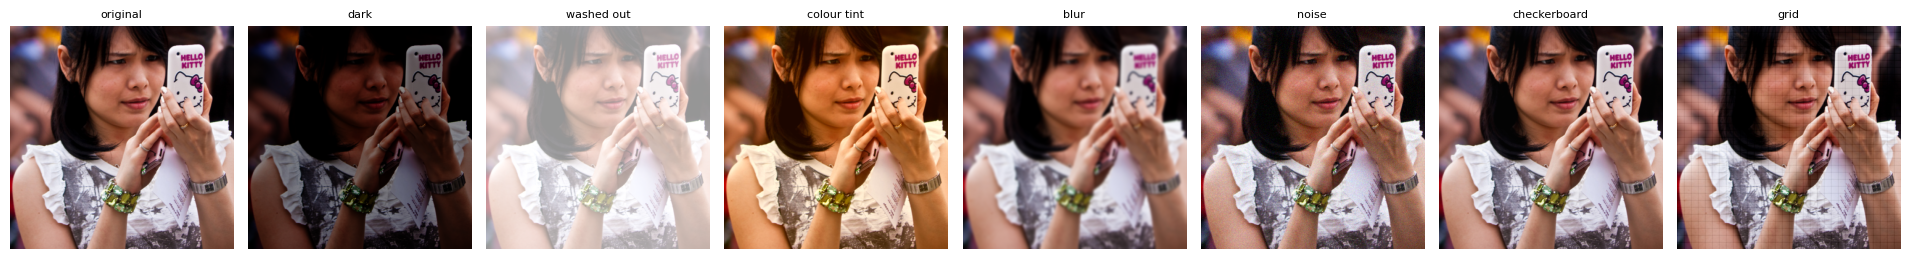

In [6]:
def degrade(rgb, kind, rng):
    """Synthetic versions of things that go wrong with generated pictures."""
    f = rgb.astype(np.float32)
    h, w = rgb.shape[:2]
    if kind == "dark":
        out = 255 * (f / 255) ** 2.2 * 0.55
    elif kind == "bright":
        out = f * 0.45 + 150
    elif kind == "low_contrast":
        out = (f - f.mean()) * 0.3 + f.mean()
    elif kind == "colour_cast":
        out = f + np.array([28, 6, -28], np.float32)
    elif kind == "cast_mild":
        out = f + np.array([14, 3, -14], np.float32)
    elif kind == "blur":
        out = cv2.GaussianBlur(f, (0, 0), 2.5)
    elif kind == "blur_mild":
        out = cv2.GaussianBlur(f, (0, 0), 1.5)
    elif kind == "noise":
        out = f + rng.normal(0, 12, f.shape)
    elif kind == "noise_mild":
        out = f + rng.normal(0, 6, f.shape)
    elif kind == "blank":
        out = np.full_like(f, 4) + rng.normal(0, 0.5, f.shape)
    elif kind == "checkerboard":
        yy, xx = np.mgrid[:h, :w]
        out = f + 7 * ((-1.0) ** (xx + yy))[..., None]
    elif kind == "grid":
        out = f.copy()
        out[::16] -= 25
        out[:, ::16] -= 25
    else:
        raise ValueError(kind)
    return np.clip(out, 0, 255).astype(np.uint8)

# Which flag(s) count as "caught" for each kind of damage
EXPECT = {"dark": {"too_dark"}, "bright": {"too_bright", "low_contrast"}, "low_contrast": {"low_contrast"},
          "colour_cast": {"colour_cast"}, "cast_mild": {"colour_cast"}, "blur": {"blurry"}, "blur_mild": {"blurry"},
          "noise": {"noisy"}, "noise_mild": {"noisy"}, "blank": {"blank"},
          "checkerboard": {"periodic_artifact"}, "grid": {"periodic_artifact"}}

def show_row(images, titles, size=3.2, path=None):
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size + 0.6))
    for ax, im, t in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(im, cmap=None if im.ndim == 3 else "magma")
        ax.set_title(textwrap.fill(t, 30), fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    if path:
        plt.savefig(path, dpi=120)
    plt.show()

show_row([photos[0]] + [degrade(photos[0], k, rng) for k in ["dark", "bright", "colour_cast", "blur", "noise", "checkerboard", "grid"]],
         ["original", "dark", "washed out", "colour tint", "blur", "noise", "checkerboard", "grid"],
         size=2.4, path=FIG / "damage_examples.png")

## 6 · Demo: one picture through the whole pipeline (intermediate visualisations)

Flags found : ['too_dark', 'noisy', 'periodic_artifact']
Fixes tried : ['notch filter (removed 12 spectrum spikes)', 'gamma on brightness (gamma 0.46)']
Decision    : fix kept: solved ['too_dark', 'noisy', 'periodic_artifact']
Time        : 585 ms


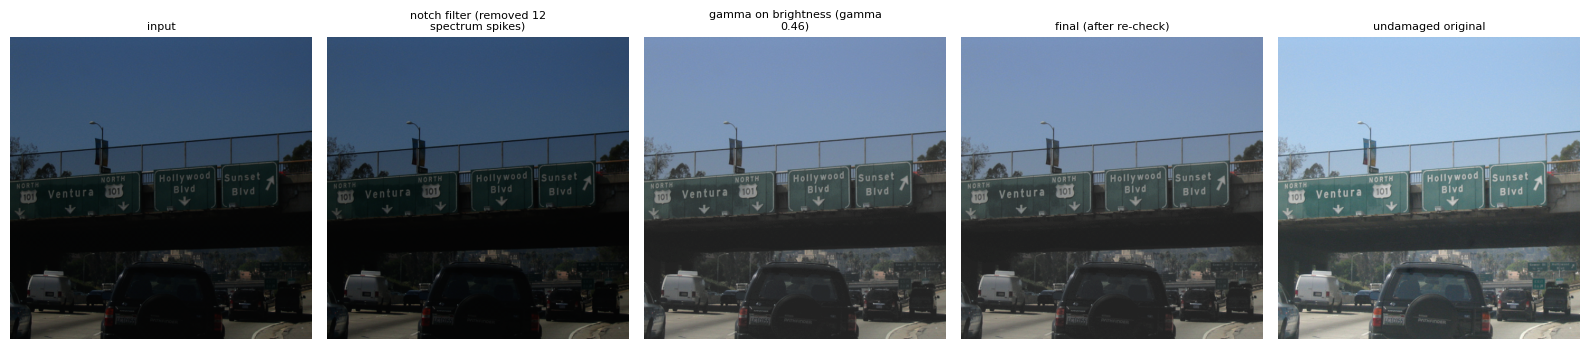

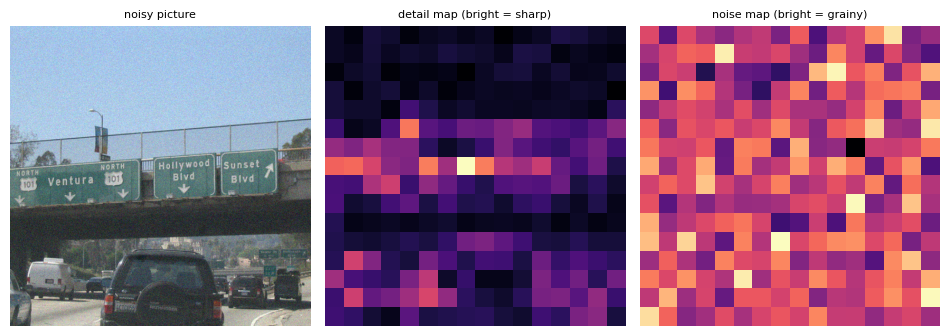

In [7]:
demo_in = degrade(degrade(photos[5], "dark", rng), "checkerboard", rng)   # two problems at once
demo_out, info = pcv.safe_enhance(demo_in, return_stages=True)
print("Flags found :", info["before"]["flags"])
print("Fixes tried :", info["actions"])
print("Decision    :", info["decision"])
print(f"Time        : {info['ms']:.0f} ms")
stages = info["stages"] + [("final (after re-check)", demo_out), ("undamaged original", photos[5])]
show_row([s[1] for s in stages], [s[0] for s in stages], path=FIG / "demo_stages.png")

maps = pcv.quality_maps(degrade(photos[5], "noise", rng))
show_row([degrade(photos[5], "noise", rng), maps["detail"], maps["noise"]],
         ["noisy picture", "detail map (bright = sharp)", "noise map (bright = grainy)"], path=FIG / "quality_maps.png")

## 7 · Experiment 1 + 2: detection and repair on held-out photos

,caught,fix_kept,escalated,psnr_damaged,psnr_after,ssim_damaged,ssim_after,ms
damage,,,,,,,,
dark,0.900,0.900,0.025,9.462,15.575,0.405,0.792,200.843
bright,1.000,0.975,0.050,8.871,15.639,0.668,0.840,216.919
low_contrast,0.950,0.900,0.025,15.263,16.531,0.708,0.837,215.976
colour_cast,0.700,0.625,0.100,21.282,23.875,0.965,0.961,146.480
cast_mild,0.150,0.150,0.100,27.115,27.114,0.980,0.979,133.054
blur,1.000,0.075,1.000,25.502,24.503,0.744,0.739,231.819
blur_mild,1.000,0.100,1.000,28.284,27.019,0.839,0.834,198.980
noise,1.000,0.950,0.050,26.794,29.575,0.706,0.871,256.315
noise_mild,0.925,0.950,0.000,32.680,34.594,0.889,0.946,254.957



False-alarm rate on 40 clean held-out photos: 15.0%
False alarms by flag:
blurry               4
colour_cast          3
too_dark             1
periodic_artifact    1


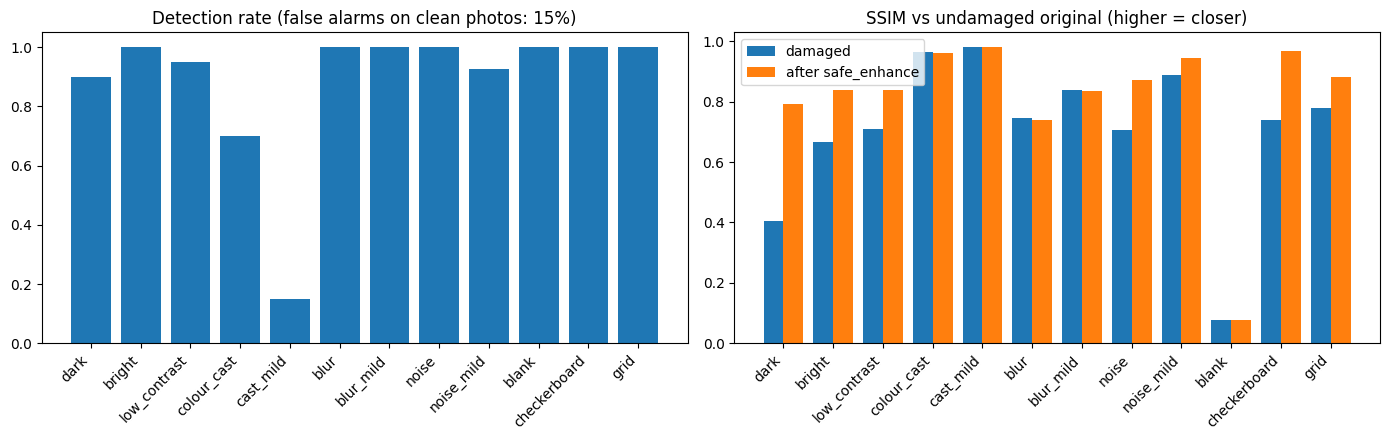

In [8]:
rows = []
for kind, expected in EXPECT.items():
    for i, im in enumerate(photos):
        x = degrade(im, kind, rng)
        out, info = pcv.safe_enhance(x)
        rows.append(dict(damage=kind, img=i, caught=bool(expected & set(info["before"]["flags"])),
                         flags=",".join(info["before"]["flags"]), fix_kept=info["accepted"], escalated=info["escalate"],
                         psnr_damaged=pcv.psnr(im, x), psnr_after=pcv.psnr(im, out),
                         ssim_damaged=pcv.ssim(im, x), ssim_after=pcv.ssim(im, out), ms=info["ms"]))
det = pd.DataFrame(rows)
summary = det.groupby("damage", sort=False).agg(
    caught=("caught", "mean"), fix_kept=("fix_kept", "mean"), escalated=("escalated", "mean"),
    psnr_damaged=("psnr_damaged", "mean"), psnr_after=("psnr_after", "mean"),
    ssim_damaged=("ssim_damaged", "mean"), ssim_after=("ssim_after", "mean"), ms=("ms", "mean"))
display(summary.round(3))
det.to_csv(OUT / "detection_repair_all.csv", index=False)
summary.to_csv(OUT / "detection_repair_summary.csv")

# False alarms: clean photos that got any flag
clean_reports = [pcv.assess(im) for im in photos]
false_alarm = np.mean([bool(r["flags"]) for r in clean_reports])
flag_counts = pd.Series([f for r in clean_reports for f in r["flags"]]).value_counts()
print(f"\nFalse-alarm rate on {len(photos)} clean held-out photos: {false_alarm:.1%}")
if len(flag_counts):
    print("False alarms by flag:\n" + flag_counts.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(summary))
axes[0].bar(x, summary["caught"], color="tab:blue")
axes[0].set_xticks(x)
axes[0].set_xticklabels(summary.index, rotation=45, ha="right")
axes[0].set_ylim(0, 1.05)
axes[0].set_title(f"Detection rate (false alarms on clean photos: {false_alarm:.0%})")
axes[1].bar(x - 0.2, summary["ssim_damaged"], 0.4, label="damaged")
axes[1].bar(x + 0.2, summary["ssim_after"], 0.4, label="after safe_enhance")
axes[1].set_xticks(x)
axes[1].set_xticklabels(summary.index, rotation=45, ha="right")
axes[1].set_title("SSIM vs undamaged original (higher = closer)")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG / "detection_repair.png", dpi=130)
plt.show()

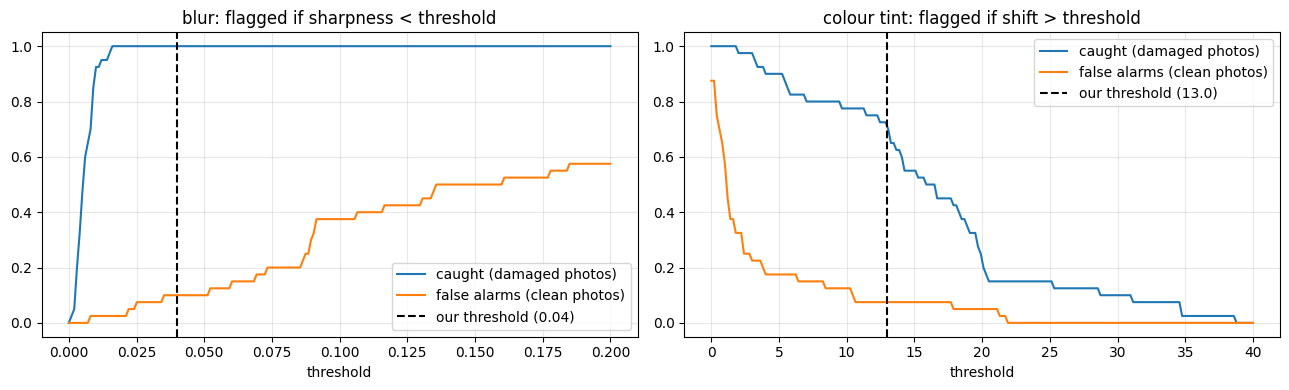

In [9]:
# The trade-off behind the two hardest thresholds, shown on held-out photos (thresholds were NOT re-tuned here).
# Moving a threshold catches more damage but also raises more false alarms on clean photos.
sharp_clean = np.array([r["metrics"]["sharpness"] for r in clean_reports])
sharp_blur = np.array([pcv.assess(degrade(im, "blur_mild", rng))["metrics"]["sharpness"] for im in photos])
cast_clean = np.array([r["metrics"]["cast_gray"] for r in clean_reports])
cast_tint = np.array([pcv.assess(degrade(im, "colour_cast", rng))["metrics"]["cast_gray"] for im in photos])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, clean_v, bad_v, th, below, ts) in zip(axes, [
        ("blur: flagged if sharpness < threshold", sharp_clean, sharp_blur, pcv.TH["blur"], True, np.linspace(0, 0.2, 200)),
        ("colour tint: flagged if shift > threshold", cast_clean, cast_tint, pcv.TH["cast_gray"], False, np.linspace(0, 40, 200))]):
    caught = [(bad_v < t).mean() if below else (bad_v > t).mean() for t in ts]
    false_al = [(clean_v < t).mean() if below else (clean_v > t).mean() for t in ts]
    ax.plot(ts, caught, label="caught (damaged photos)")
    ax.plot(ts, false_al, label="false alarms (clean photos)")
    ax.axvline(th, color="k", ls="--", label=f"our threshold ({th})")
    ax.set_title(name)
    ax.set_xlabel("threshold")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(FIG / "threshold_tradeoff.png", dpi=130)
plt.show()

**How to read this:**
- **caught:** share of damaged photos where the right problem was flagged.
- **fix_kept:** share where the fix passed the re-check (accept-or-revert).
- **escalated:** share sent back to the generator, because classical CV can't really fix it (real blur, blank). That's the expected behaviour for those rows, not a failure.
- Repair works when `ssim_after > ssim_damaged`. For blur, it should stay about the same, because the fix gets rejected and the picture is escalated instead.
- **False alarms** are mostly "blurry" on photos with soft backgrounds, and "tint" on warm scenes. A false blur alarm doesn't change the picture (the sharpen fix gets rejected), but in the cascade it costs an **unnecessary regeneration**. The trade-off chart above shows the price of moving each threshold.

## 8 · Experiment 3: do no harm (clean pictures should be left alone)

Clean held-out photos left untouched: 36/40 (90%)
  photo 1: fix kept: solved ['too_dark', 'colour_cast']
  photo 12: fix kept: solved ['colour_cast']; still ['blurry']: escalate to a higher rung
  photo 13: fix kept: solved ['periodic_artifact']
  photo 28: fix kept: solved ['colour_cast']; still ['blurry']: escalate to a higher rung


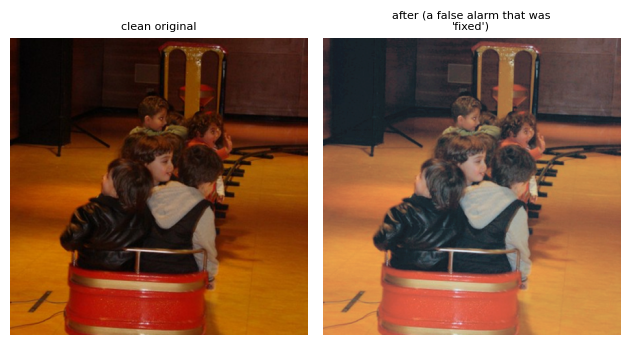

Downloading: "https://github.com/photosynthesis-team/piq/releases/download/v0.4.0/brisque_svm_weights.pt" to /root/.cache/torch/hub/checkpoints/brisque_svm_weights.pt


100%|██████████| 112k/112k [00:00<00:00, 26.3MB/s]



BRISQUE on 105 kept fixes (lower = better): before 45.5 -> after 18.5; improved in 84% of cases


In [10]:
def brisque(imgs):
    """Independent no-reference quality score (lower = better). Not used by our checks, only to double-check them."""
    import torch, piq
    x = torch.from_numpy(np.stack(imgs)).permute(0, 3, 1, 2).float() / 255.0
    return piq.brisque(x, data_range=1.0, reduction="none").numpy()

untouched, changed = 0, []
for i, im in enumerate(photos):
    out, info = pcv.safe_enhance(im)
    if np.array_equal(out, im):
        untouched += 1
    else:
        changed.append((i, info["decision"], out))
print(f"Clean held-out photos left untouched: {untouched}/{len(photos)} ({untouched / len(photos):.0%})")
for i, decision, _ in changed:
    print(f"  photo {i}: {decision}")
if changed:
    show_row([photos[changed[0][0]], changed[0][2]], ["clean original", "after (a false alarm that was 'fixed')"],
             path=FIG / "do_no_harm_example.png")

# Independent double-check on damaged photos where a fix was kept: did BRISQUE improve?
if IQA_OK:
    try:
        before, after = [], []
        for kind in ["dark", "bright", "low_contrast", "colour_cast", "noise", "noise_mild", "checkerboard", "grid"]:
            for im in photos[:15]:
                x = degrade(im, kind, rng)
                out, info = pcv.safe_enhance(x)
                if info["accepted"]:
                    before.append(x)
                    after.append(out)
        b, a = brisque(before), brisque(after)
        print(f"\nBRISQUE on {len(b)} kept fixes (lower = better): before {b.mean():.1f} -> after {a.mean():.1f}; "
              f"improved in {np.mean(a < b):.0%} of cases")
    except Exception as e:
        print("BRISQUE check skipped:", e)

## 9 · Experiment 4: prompt-aware exceptions (don't "fix" what the prompt asked for)

In [11]:
dark = degrade(photos[2], "dark", rng)
for prompt in [None, "a quiet street at night", "a moody noir scene in a dark alley"]:
    r = pcv.assess(dark, prompt)
    print(f"prompt={prompt!r:42s} flags={r['flags']}  ignored_by_prompt={r['ignored_by_prompt']}")
warm = degrade(photos[2], "colour_cast", rng)
for prompt in [None, "a warm sunset over the city"]:
    r = pcv.assess(warm, prompt)
    print(f"prompt={prompt!r:42s} flags={r['flags']}  ignored_by_prompt={r['ignored_by_prompt']}")

prompt=None                                       flags=['too_dark']  ignored_by_prompt=[]
prompt='a quiet street at night'                  flags=[]  ignored_by_prompt=['too_dark']
prompt='a moody noir scene in a dark alley'       flags=[]  ignored_by_prompt=['too_dark']
prompt=None                                       flags=['colour_cast']  ignored_by_prompt=[]
prompt='a warm sunset over the city'              flags=[]  ignored_by_prompt=['colour_cast']


## 10 · Experiment 5 + 6: upscaling and packing for phones

psnr           ssim       
factor          x2      x4     x2     x4
method                                  
bicubic     32.246  27.040  0.922  0.790
bilinear    30.691  26.241  0.898  0.770
edge_aware  32.802  27.363  0.929  0.798
lanczos     32.489  27.133  0.923  0.790
nearest     29.790  25.356  0.902  0.749

edge_aware 512 -> 1024 takes 68 ms


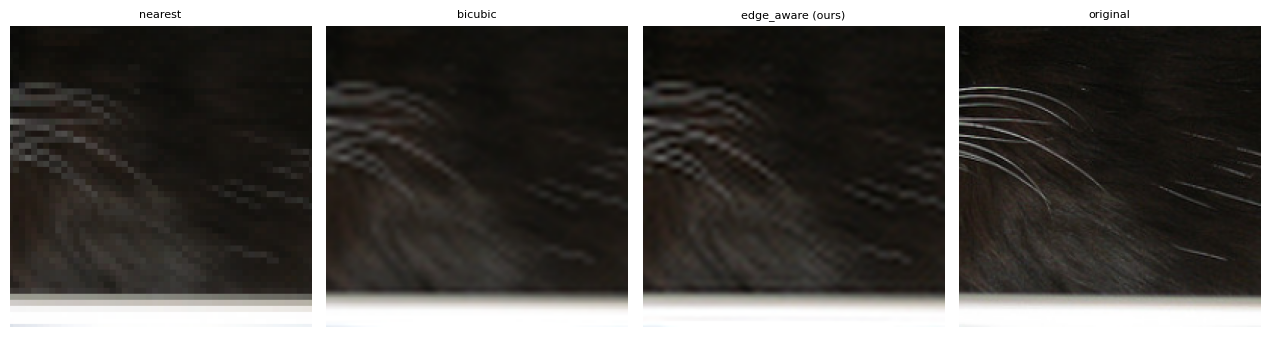

,kb,ssim,ms,download_s_4G (10 Mbps),download_s_slow 3G (1.5 Mbps)
option,,,,,
PNG,953.557,1.000,483.253,0.763,5.086
JPEG q90,164.027,0.994,7.500,0.131,0.875
WebP q80,61.394,0.979,185.727,0.049,0.327
smart WEBP (SSIM>=0.95),36.606,0.977,556.952,0.029,0.195
smart JPG (SSIM>=0.95),68.491,0.983,160.268,0.055,0.365


In [12]:
up_rows = []
for factor in (2, 4):
    small = 512 // factor
    for method in ["nearest", "bilinear", "bicubic", "lanczos", "edge_aware"]:
        ps, ss, ts = [], [], []
        for im in photos:
            lr = cv2.resize(im, (small, small), interpolation=cv2.INTER_AREA)
            t0 = time.perf_counter()
            up = pcv.upscale(lr, (512, 512), method)
            ts.append((time.perf_counter() - t0) * 1000)
            ps.append(pcv.psnr(im, up))
            ss.append(pcv.ssim(im, up))
        up_rows.append(dict(factor=f"x{factor}", method=method, psnr=np.mean(ps), ssim=np.mean(ss), ms=np.mean(ts)))
up = pd.DataFrame(up_rows)
display(up.pivot(index="method", columns="factor", values=["psnr", "ssim"]).round(3))
up.to_csv(OUT / "upscaling.csv", index=False)
t0 = time.perf_counter()
big = pcv.upscale(photos[0], (1024, 1024), "edge_aware")
print(f"edge_aware 512 -> 1024 takes {(time.perf_counter() - t0) * 1000:.0f} ms")

lr = cv2.resize(photos[7], (128, 128), interpolation=cv2.INTER_AREA)
crops = [pcv.upscale(lr, (512, 512), m)[150:350, 150:350] for m in ["nearest", "bicubic", "edge_aware"]]
show_row(crops + [photos[7][150:350, 150:350]], ["nearest", "bicubic", "edge_aware (ours)", "original"],
         path=FIG / "upscaling_crops.png")

# Packing for phones: what does the user download?
pack_rows = []
for im in photos[:10]:
    big = pcv.upscale(im, (1024, 1024), "edge_aware")
    for name, fmt, q in [("PNG", "png", 0), ("JPEG q90", "jpg", 90), ("WebP q80", "webp", 80)]:
        t0 = time.perf_counter()
        data = pcv.encode(big, fmt, q)
        ms = (time.perf_counter() - t0) * 1000
        pack_rows.append(dict(option=name, kb=len(data) / 1024, ssim=pcv.ssim(big, pcv.decode(data)), ms=ms))
    for fmt in ("webp", "jpg"):
        data, info = pcv.pack_for_mobile(big, fmt=fmt, min_ssim=0.95)
        pack_rows.append(dict(option=f"smart {fmt.upper()} (SSIM>=0.95)", kb=info["kb"], ssim=info["ssim"], ms=info["ms"]))
pack = pd.DataFrame(pack_rows).groupby("option", sort=False).mean()
for label, mbps in [("4G (10 Mbps)", 10), ("slow 3G (1.5 Mbps)", 1.5)]:
    pack[f"download_s_{label}"] = pack["kb"] * 8 / 1000 / mbps
display(pack.round(3))
pack.to_csv(OUT / "packing.csv")

## 11 · Experiment 7: real generated pictures from notebook 01

,pictures,ok,flagged,fix_kept,escalated,ms
setup,,,,,,
B0_teacher_20step,12,0.750,0.250,0.250,0.000,154.139
F1_fallback_lowmem,12,0.833,0.167,0.083,0.083,120.753
M1_lowmem_1024,12,0.750,0.250,0.167,0.083,115.708
M2_lowmem_768,12,0.917,0.083,0.000,0.083,73.823
M3_lowmem_1024_tr4bit,12,0.833,0.167,0.167,0.000,92.805
S10_noCHI,12,0.750,0.250,0.250,0.000,96.675
S1_sprint_2step,12,0.667,0.333,0.250,0.083,104.096
S2_sprint_1step,12,0.750,0.250,0.167,0.083,85.232
S3_sprint_4step,12,0.750,0.250,0.167,0.083,92.632


Most common flags on generated pictures:
blurry               13
periodic_artifact    11
too_dark             10
colour_cast           7


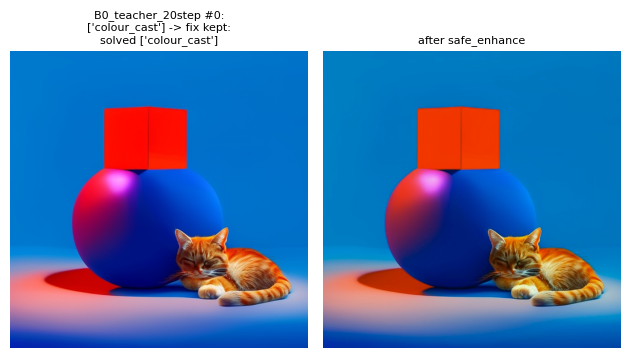

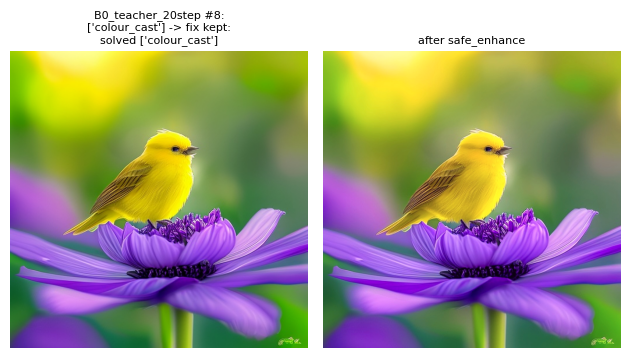

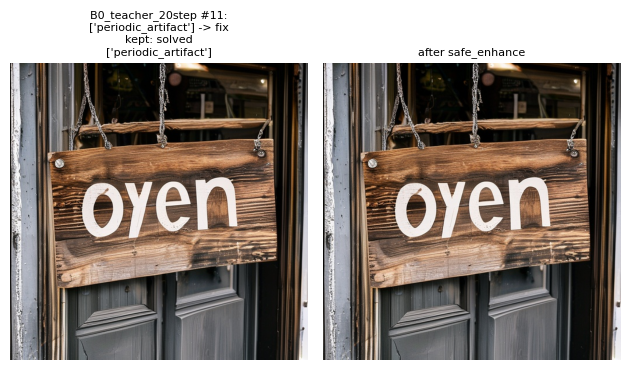

In [13]:
if generated:
    g_rows, flagged_examples = [], []
    for setup, k, prompt, rgb in generated:
        out, info = pcv.safe_enhance(rgb, prompt)
        b = info["before"]
        g_rows.append(dict(setup=setup, prompt_idx=k, verdict=b["verdict"], flags=",".join(b["flags"]),
                           ignored=",".join(b["ignored_by_prompt"]), fix_kept=info["accepted"],
                           escalated=info["escalate"], ms=info["ms"]))
        if b["flags"] and len(flagged_examples) < 6:
            flagged_examples.append((rgb, out, f"{setup} #{k}: {b['flags']} -> {info['decision'][:60]}"))
    gen = pd.DataFrame(g_rows)
    per_setup = gen.groupby("setup").agg(pictures=("verdict", "size"),
                                         ok=("verdict", lambda v: (v == "ok").mean()),
                                         flagged=("verdict", lambda v: (v != "ok").mean()),
                                         fix_kept=("fix_kept", "mean"), escalated=("escalated", "mean"),
                                         ms=("ms", "mean"))
    display(per_setup.round(3))
    all_flags = pd.Series([f for s in gen["flags"] for f in s.split(",") if f]).value_counts()
    print("Most common flags on generated pictures:\n" + (all_flags.to_string() if len(all_flags) else "none"))
    gen.to_csv(OUT / "generated_flags.csv", index=False)
    for before_img, after_img, title in flagged_examples[:3]:
        show_row([before_img, after_img], [title, "after safe_enhance"])
else:
    print("Skipped: notebook 01 hasn't saved pictures to Drive yet. Re-run this section later.")

## 12 · Speed summary and saved results

In [14]:
def timeit(fn, n=5):
    t0 = time.perf_counter()
    for _ in range(n):
        fn()
    return (time.perf_counter() - t0) / n * 1000

img512 = photos[0]
img1024 = pcv.upscale(photos[0], (1024, 1024), "lanczos")
dark1024 = degrade(img1024, "dark", rng)
speed = pd.DataFrame([
    dict(step="assess (visual check)", ms_512=timeit(lambda: pcv.assess(img512)), ms_1024=timeit(lambda: pcv.assess(img1024))),
    dict(step="safe_enhance, clean picture", ms_512=timeit(lambda: pcv.safe_enhance(img512)), ms_1024=timeit(lambda: pcv.safe_enhance(img1024))),
    dict(step="safe_enhance, dark picture", ms_512=timeit(lambda: pcv.safe_enhance(degrade(img512, "dark", rng))), ms_1024=timeit(lambda: pcv.safe_enhance(dark1024))),
    dict(step="upscale x2 (edge_aware)", ms_512=timeit(lambda: pcv.upscale(cv2.resize(img512, (256, 256)), (512, 512))), ms_1024=timeit(lambda: pcv.upscale(img512, (1024, 1024)))),
    dict(step="pack_for_mobile (smart WebP)", ms_512=timeit(lambda: pcv.pack_for_mobile(img512), 3), ms_1024=timeit(lambda: pcv.pack_for_mobile(img1024), 3)),
]).set_index("step")
display(speed.round(1))
speed.to_csv(OUT / "speed.csv")

lines = ["# Notebook 02a results: classical CV layer (visual quality)", "",
         f"Held-out COCO photos: {len(photos)} (thresholds tuned on 12 different photos). CPU only.", "",
         "## Detection and repair", "", summary.round(3).to_markdown(), "",
         f"False-alarm rate on clean held-out photos: {false_alarm:.1%}; clean photos left untouched: "
         f"{untouched}/{len(photos)}", "",
         "## Upscaling", "", up.round(3).to_markdown(index=False), "",
         "## Packing for phones", "", pack.round(3).to_markdown(), "",
         "## Speed (ms)", "", speed.round(1).to_markdown(), ""]
if generated:
    lines += ["## Generated pictures from notebook 01", "", per_setup.round(3).to_markdown(), ""]
(OUT / "02a_summary.md").write_text("\n".join(lines))
print("Saved summary + CSVs + figures to", OUT)

,ms_512,ms_1024
step,,
assess (visual check),61.1,59.1
"safe_enhance, clean picture",62.3,59.2
"safe_enhance, dark picture",143.6,154.7
upscale x2 (edge_aware),16.0,65.3
pack_for_mobile (smart WebP),383.3,489.7


Saved summary + CSVs + figures to /content/drive/MyDrive/P3_T2I/02a_classical_cv


## 13 · How to read this, and the honest limitations

- **What it's good at:** dark/washed-out/flat pictures, mild grain and grid/checkerboard glitches are caught *and* repaired (higher SSIM/PSNR), and clean pictures are mostly left alone.
- **What it can't do:**
  - **Real blur:** sharpening can't recover detail that isn't there. The picture is **escalated** to the generator for more steps instead. That's by design, and it's what feeds the cascade.
  - **Colour tint vs a warm scene:** a brown bear or lamp light looks like a tint to any colour-cast test. So the tint check is deliberately **conservative** (strong tints only), and prompt words like "warm", "sunset" or "autumn" switch it off. Expect a few false alarms here; it's one of our documented failure cases.
  - **Prompt match:** nothing here knows whether the white cat is missing. That's the **semantic** check in notebook 02b.
- **Synthetic damage ≠ real generator mistakes:** that's why section 11 also runs on real generated pictures.
- **Packing trade-off:** the "smart" WebP search gives the smallest file, but costs a few hundred ms of CPU. A fixed WebP q80 is ~4× faster to make and only slightly bigger. On fast networks the fixed setting is the better deal; on slow networks the smart one wins. Pick the default for the app from the packing table.
- **Independent check:** BRISQUE (a classical no-reference score that we don't use in our own checks) double-checks that kept fixes look better.